In [1]:
import os
import tempfile
import numpy as np
import matplotlib.pyplot as plt

import tdgl
from tdgl.geometry import box, circle

from shapely.geometry import Polygon as ShapelyPolygon
from shapely.ops import unary_union

from pathlib import Path

BASE_DIR = Path.cwd()
RESULTS_DIR = BASE_DIR / "results"
H5_DIR = RESULTS_DIR / "h5"
MESH_DIR = RESULTS_DIR / "meshes"
FIGURE_DIR = RESULTS_DIR / "figures"

H5_DIR.mkdir(parents=True, exist_ok=True)
MESH_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

# ============================================================
# LOAD SAVED SOLUTIONS FOR POST-PROCESSING
# ============================================================

solution_no_hole = tdgl.Solution.from_hdf5(
    str(H5_DIR / "transport_no_hole.h5")
)

solution_hole = tdgl.Solution.from_hdf5(
    str(H5_DIR / "transport_hole.h5")
)

In [2]:
def plot_hole_zoom(solution, title):
    # Dense plotting grid around the 100 nm hole.
    # The hole is centered at x = 0, y = 0.
    x = np.linspace(-0.08, 0.08, 500)
    y = np.linspace(-0.15, 0.15, 700)
    X, Y = np.meshgrid(x, y)

    positions = np.column_stack((X.ravel(), Y.ravel()))

    # Complex order parameter at all plotting points
    psi = solution.interp_order_parameter(
        positions,
        method="linear",
    ).reshape(X.shape)

    # Mask points outside the superconducting film,
    # including the hole itself.
    valid = solution.device.contains_points(positions).reshape(X.shape)

    psi = np.asarray(psi, dtype=complex)
    psi[~valid] = np.nan

    amplitude = np.abs(psi)
    print("Amplitude range:")
    print("min =", np.nanmin(amplitude))
    print("max =", np.nanmax(amplitude))
    phase = np.angle(psi)

    # Current density interpolated on the same dense grid
    current = solution.interp_current_density(
        positions,
        method="linear",
        with_units=False,
    ).reshape(X.shape + (2,))

    Kx = current[:, :, 0]
    Ky = current[:, :, 1]

    Kx[~valid] = np.nan
    Ky[~valid] = np.nan
    current_magnitude = np.sqrt(Kx**2 + Ky**2)

    fig, axes = plt.subplots(
        1,
        3,
        figsize=(16, 5),
        constrained_layout=True,
    )

    # |psi|
    image0 = axes[0].pcolormesh(
        X,
        Y,
        amplitude,
        shading="auto",
        cmap="viridis",
        vmin=0,
        vmax=1,
    )
    axes[0].set_title(r"$|\psi|$")
    fig.colorbar(image0, ax=axes[0])

    # Phase
    image1 = axes[1].pcolormesh(
        X,
        Y,
        phase / np.pi,
        shading="auto",
        cmap="twilight",
        vmin=-1,
        vmax=1,
    )
    axes[1].set_title(r"$\arg(\psi)/\pi$")
    fig.colorbar(image1, ax=axes[1])

    # Current magnitude plus streamlines
    image2 = axes[2].pcolormesh(
        X,
        Y,
        current_magnitude,
        shading="auto",
        cmap="magma",
    )

    # Replace invalid values with zero only for streamplotting.
    # They are already masked in the color plot.
    Kx_stream = np.nan_to_num(Kx, nan=0.0)
    Ky_stream = np.nan_to_num(Ky, nan=0.0)

    axes[2].streamplot(
        x,
        y,
        Kx_stream,
        Ky_stream,
        color="white",
        density=2.0,
        linewidth=0.7,
        arrowsize=0.8,
    )

    axes[2].set_title(r"$|\mathbf{K}|$ and streamlines")
    fig.colorbar(image2, ax=axes[2])

    for ax in axes:
        ax.set_xlim(-0.08, 0.08)
        ax.set_ylim(-0.15, 0.15)
        ax.set_aspect("equal")
        ax.set_xlabel(r"$x\ [\mu\mathrm{m}]$")
        ax.set_ylabel(r"$y\ [\mu\mathrm{m}]$")

    fig.suptitle(title)
    plt.show()
    plt.close(fig)

    

Amplitude range:
min = 0.9897229173588847
max = 0.9957343100754564


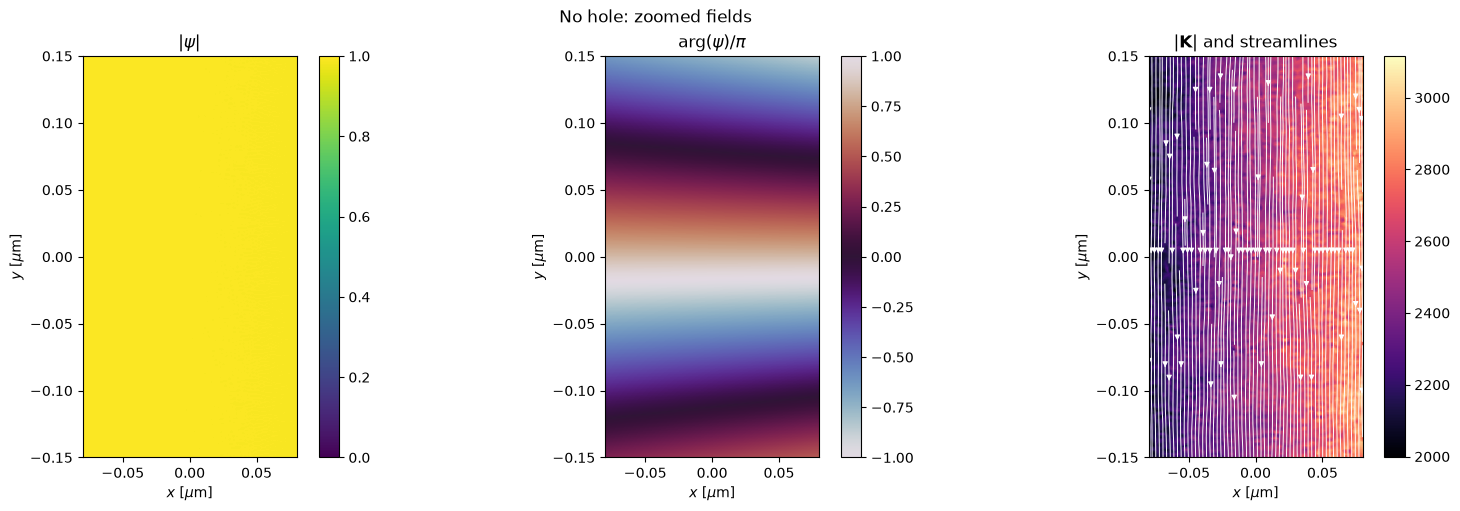

Amplitude range:
min = 0.949250374729997
max = 0.9998157008430121


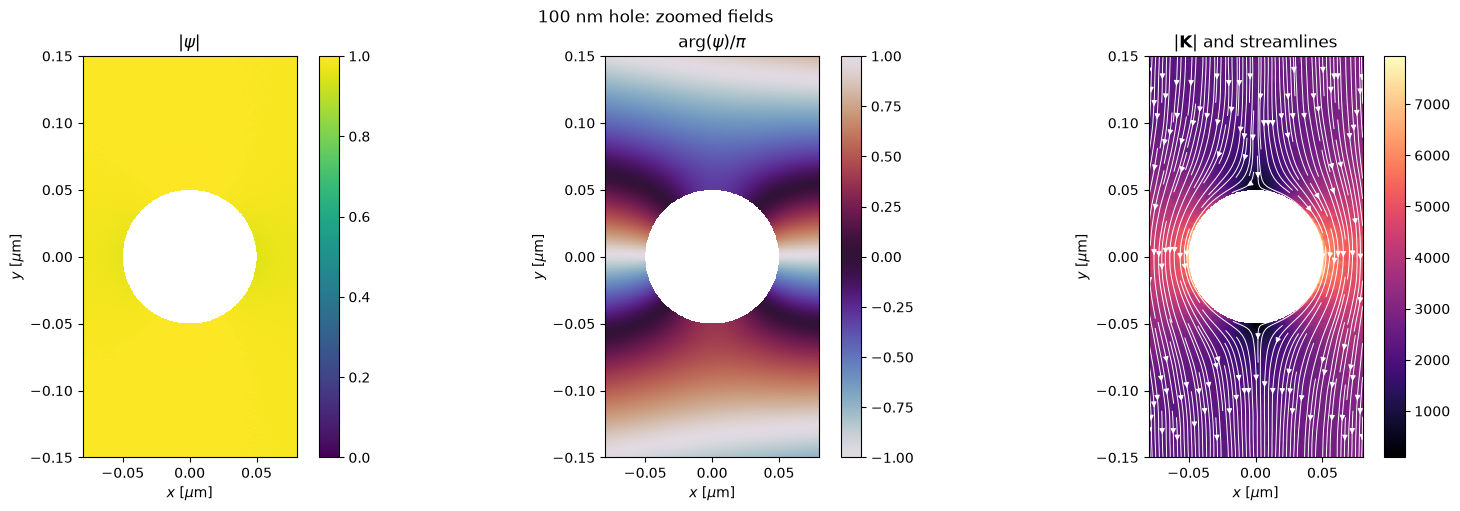

[1.000000e-02 1.100000e-01 9.450000e-01 1.288750e+00 1.651250e+00
 1.882500e+00 2.113750e+00 2.307500e+00 2.501250e+00 2.695000e+00
 2.907500e+00 3.101250e+00 3.313750e+00 3.488750e+00 3.682500e+00
 3.876250e+00 4.070000e+00 4.263750e+00 4.457500e+00 4.651250e+00
 4.863750e+00 5.057500e+00 5.251250e+00 5.445000e+00 5.638750e+00
 5.813750e+00 6.026250e+00 6.220000e+00 6.413750e+00 6.607500e+00
 6.820000e+00 7.013750e+00 7.207500e+00 7.420000e+00 7.595000e+00
 7.807500e+00 8.001250e+00 8.195000e+00 8.388750e+00 8.582500e+00
 8.795000e+00 8.988750e+00 9.201250e+00 9.376250e+00 9.588750e+00
 9.782500e+00 9.976250e+00 1.017000e+01 1.036375e+01 1.055750e+01
 1.075125e+01 1.096375e+01 1.115750e+01 1.135125e+01 1.154500e+01
 1.173875e+01 1.193250e+01 1.212625e+01 1.233875e+01 1.253250e+01
 1.272625e+01 1.292000e+01 1.311375e+01 1.330750e+01 1.350125e+01
 1.369500e+01 1.388875e+01 1.408250e+01 1.429500e+01 1.448875e+01
 1.468250e+01 1.489500e+01 1.507000e+01 1.526375e+01 1.547625e+01
 1.567000e

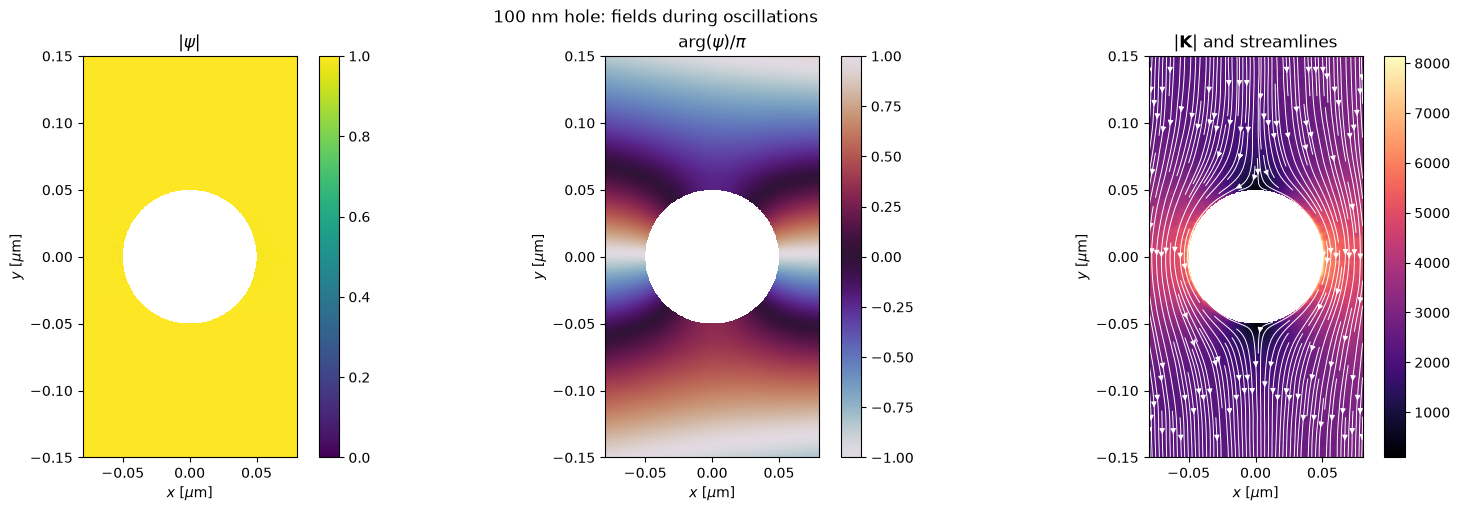

In [3]:
plot_hole_zoom(
    solution_no_hole,
    "No hole: zoomed fields"
)

plot_hole_zoom(
    solution_hole,
    "100 nm hole: zoomed fields"
)

print(solution_hole.times)

solution_hole.solve_step = solution_hole.closest_solve_step(5.0)

plot_hole_zoom(
    solution_hole,
    "100 nm hole: fields during oscillations",
)

In [4]:
def phase_winding(solution, radius=0.06, n_points=401):
    angles = np.linspace(0, 2 * np.pi, n_points)

    positions = np.column_stack(
        (
            radius * np.cos(angles),
            radius * np.sin(angles),
        )
    )

    psi_circle = solution.interp_order_parameter(
        positions,
        method="linear",
    )

    phase = np.unwrap(np.angle(psi_circle))

    winding = (phase[-1] - phase[0]) / (2 * np.pi)

    return winding, np.abs(psi_circle).min(), np.abs(psi_circle).max()

for target_time in [3.0, 5.0, 7.0, 9.0, 10.0, 12.0, 20.0]:
    solution_hole.solve_step = solution_hole.closest_solve_step(target_time)

    actual_time = solution_hole.times[solution_hole.solve_step]

    winding, psi_min, psi_max = phase_winding(
        solution_hole,
        radius=0.06,
    )

    print(
        f"t={actual_time:.3f}: "
        f"winding={winding:.3f}, "
        f"|psi| range=({psi_min:.4f}, {psi_max:.4f})"
    )
    

t=2.907: winding=0.000, |psi| range=(0.9946, 1.0000)
t=5.058: winding=0.000, |psi| range=(0.9883, 0.9999)
t=7.014: winding=0.000, |psi| range=(0.9836, 0.9998)
t=8.989: winding=0.000, |psi| range=(0.9791, 0.9997)
t=9.976: winding=0.000, |psi| range=(0.9770, 0.9996)
t=11.933: winding=0.000, |psi| range=(0.9729, 0.9995)
t=20.020: winding=0.000, |psi| range=(0.9581, 0.9992)


In [5]:
x = np.linspace(-0.08, 0.08, 500)
y = np.linspace(-0.15, 0.15, 700)
X, Y = np.meshgrid(x, y)

positions = np.column_stack((X.ravel(), Y.ravel()))

def compare_current_components_near_hole(
    solution,
    x_limits=(-0.08, 0.08),
    y_limits=(-0.15, 0.15),
    grid_size=500,
):
    xgrid, ygrid, _ = solution.grid_current_density(
        dataset=None,
        grid_shape=(grid_size, grid_size),
        method="linear",
        with_units=False,
    )

    _, _, Ks_grid = solution.grid_current_density(
        dataset="supercurrent",
        grid_shape=(grid_size, grid_size),
        method="linear",
        with_units=False,
    )

    _, _, Kn_grid = solution.grid_current_density(
        dataset="normal_current",
        grid_shape=(grid_size, grid_size),
        method="linear",
        with_units=False,
    )

    # pyTDGL returns shape (2, ny, nx)
    Kx, Ky = Ks_grid
    Ks_mag = np.hypot(Kx, Ky)

    Kx, Ky = Kn_grid
    Kn_mag = np.hypot(Kx, Ky)

    Kx, Ky = solution.grid_current_density(
        dataset=None,
        grid_shape=(grid_size, grid_size),
        method="linear",
        with_units=False,
    )[2]
    K_mag = np.hypot(Kx, Ky)

    near_hole = (
        (xgrid >= x_limits[0])
        & (xgrid <= x_limits[1])
        & (ygrid >= y_limits[0])
        & (ygrid <= y_limits[1])
    )

    def finite_values(array):
        return array[near_hole][np.isfinite(array[near_hole])]

    Ks_values = finite_values(Ks_mag)
    Kn_values = finite_values(Kn_mag)
    K_values = finite_values(K_mag)

    print("Near-hole region:")
    print(f"  x = {x_limits}")
    print(f"  y = {y_limits}")

    print("\nSupercurrent magnitude:")
    print(f"  min  = {Ks_values.min():.6g}")
    print(f"  max  = {Ks_values.max():.6g}")
    print(f"  mean = {Ks_values.mean():.6g}")

    print("\nNormal-current magnitude:")
    print(f"  min  = {Kn_values.min():.6g}")
    print(f"  max  = {Kn_values.max():.6g}")
    print(f"  mean = {Kn_values.mean():.6g}")

    print("\nTotal-current magnitude:")
    print(f"  min  = {K_values.min():.6g}")
    print(f"  max  = {K_values.max():.6g}")
    print(f"  mean = {K_values.mean():.6g}")

compare_current_components_near_hole(solution_hole)
Ks = solution_hole.interp_current_density(
    positions,
    dataset="supercurrent",
    method="linear",
    with_units=False,
).reshape(X.shape + (2,))

Kn = solution_hole.interp_current_density(
    positions,
    dataset="normal_current",
    method="linear",
    with_units=False,
).reshape(X.shape + (2,))

K = solution_hole.interp_current_density(
    positions,
    dataset=None,
    method="linear",
    with_units=False,
).reshape(X.shape + (2,))

Ks_mag = np.sqrt(Ks[:, :, 0]**2 + Ks[:, :, 1]**2)
Kn_mag = np.sqrt(Kn[:, :, 0]**2 + Kn[:, :, 1]**2)
K_mag = np.sqrt(K[:, :, 0]**2 + K[:, :, 1]**2)

print("Interpolated near-hole ranges:")
print("supercurrent:", np.nanmin(Ks_mag), np.nanmax(Ks_mag))
print("normal current:", np.nanmin(Kn_mag), np.nanmax(Kn_mag))
print("total current:", np.nanmin(K_mag), np.nanmax(K_mag))

Near-hole region:
  x = (-0.08, 0.08)
  y = (-0.15, 0.15)

Supercurrent magnitude:
  min  = 0
  max  = 7952.39
  mean = 2388.1

Normal-current magnitude:
  min  = 0
  max  = 23.6759
  mean = 2.55959

Total-current magnitude:
  min  = 0
  max  = 7976.07
  mean = 2390.63
Interpolated near-hole ranges:
supercurrent: 0.0 7917.787419359681
normal current: 0.0 23.46439496194238
total current: 0.0 7940.3515161330615


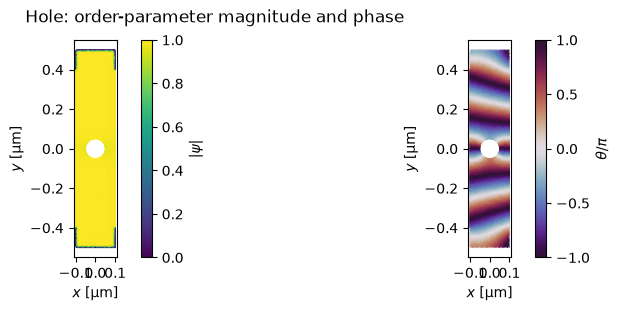

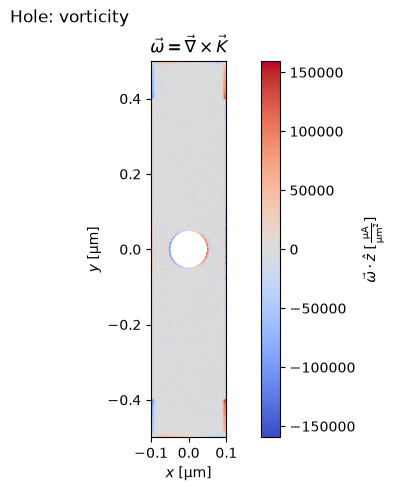

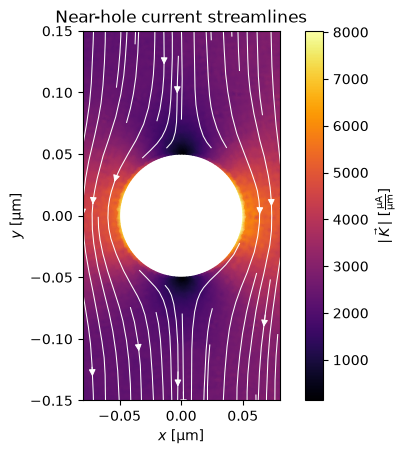

In [6]:
import matplotlib.pyplot as plt

fig, axes = solution_hole.plot_order_parameter()
fig.suptitle("Hole: order-parameter magnitude and phase")
plt.show()

fig, axes = solution_hole.plot_vorticity()
fig.suptitle("Hole: vorticity")
plt.show()

fig, ax = solution_hole.plot_currents(streamplot=True)
ax.set_xlim(-0.08, 0.08)
ax.set_ylim(-0.15, 0.15)
ax.set_aspect("equal")
ax.set_title("Near-hole current streamlines")
plt.show()